#  Predicting On-Time Shipment Delivery

**Steps covered:**

1. Load data
2. Exploratory Data Analysis (EDA)
3. Feature/target split
4. Train/test split
5. Preprocessing (scaling + encoding) - fit on train, apply to both
6. Train multiple models
7. Compare models
8. Hyperparameter tuning
9. Final evaluation
10. Save the model + preprocessing objects

In [177]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

## 1. Load Data

import pandas as pd → Imports the Pandas library.
pd.read_csv() → Reads the CSV file.
df → Stores the dataset in a DataFrame.
df.head() → Displays the first 5 rows of the dataset.

In [178]:
df = pd.read_csv(r'C:\Users\pkavy\OneDrive\Desktop\ML\Train.csv')

### Display First 5 Rows

The df.head() function is used to display the first 5 rows of the dataset.
It helps us quickly check the dataset and understand its columns and values.


In [179]:
df.head()

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


### Dataset Information

The df.info() function is used to display information about the dataset, such as the number of rows, columns, data types, and missing values.
 Shows the total number of rows and columns.
 Displays column names.
 Shows the data type of each column.
 Shows the number of non-null values.
 Helps identify missing values.


In [180]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   10999 non-null  int64
 1   Warehouse_block      10999 non-null  str  
 2   Mode_of_Shipment     10999 non-null  str  
 3   Customer_care_calls  10999 non-null  int64
 4   Customer_rating      10999 non-null  int64
 5   Cost_of_the_Product  10999 non-null  int64
 6   Prior_purchases      10999 non-null  int64
 7   Product_importance   10999 non-null  str  
 8   Gender               10999 non-null  str  
 9   Discount_offered     10999 non-null  int64
 10  Weight_in_gms        10999 non-null  int64
 11  Reached.on.Time_Y.N  10999 non-null  int64
dtypes: int64(8), str(4)
memory usage: 1.0 MB


### Statistical Summary

The df.describe() function is used to generate a statistical summary of the numerical columns in the dataset.
It provides:
count – Number of non-null values
mean – Average value
std – Standard deviation
min – Minimum value
25% – First quartile (Q1)
50% – Median (Q2)
75% – Third quartile (Q3)
max – Maximum value
It helps us understand the distribution and basic statistics of the numerical data.


In [181]:
df.describe()

,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999.00000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000
mean,5500.00000,4.054459,2.990545,210.196836,3.567597,13.373216,3634.016729,0.596691
std,3175.28214,1.141490,1.413603,48.063272,1.522860,16.205527,1635.377251,0.490584
min,1.00000,2.000000,1.000000,96.000000,2.000000,1.000000,1001.000000,0.000000
25%,2750.50000,3.000000,2.000000,169.000000,3.000000,4.000000,1839.500000,0.000000
50%,5500.00000,4.000000,3.000000,214.000000,3.000000,7.000000,4149.000000,1.000000
75%,8249.50000,5.000000,4.000000,251.000000,4.000000,10.000000,5050.000000,1.000000
max,10999.00000,7.000000,5.000000,310.000000,10.000000,65.000000,7846.000000,1.000000


In [182]:
cat_cols = df.select_dtypes(include=['object', 'category']).columns

print("Categorical Columns:")
print(cat_cols)

Categorical Columns:
Index(['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender'], dtype='str')


C:\Users\pkavy\AppData\Local\Temp\ipykernel_20452\3823065783.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns


In [183]:
df[cat_cols].describe()

,Warehouse_block,Mode_of_Shipment,Product_importance,Gender
count,10999,10999,10999,10999
unique,5,3,3,2
top,F,Ship,low,F
freq,3666,7462,5297,5545


### Statistical Summary of All Columns

The df.describe(include=all) function is used to generate a statistical summary of both numerical and categorical columns in the dataset.
It provides:
count – Number of non-null values
mean – Average of numerical values
std– Standard deviation
min – Minimum value
25%– First quartile
50% – Median
75% – Third quartile
max – Maximum value
unique – Number of unique values in categorical columns
top – Most frequently occurring value
freq – Frequency of the most common value
It helps us understand the overall statistical characteristics of all columns, including both numerical and categorical data.


In [184]:
df.describe(include='all')

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999.00000,10999,10999,10999.000000,10999.000000,10999.000000,10999.000000,10999,10999,10999.000000,10999.000000,10999.000000
unique,NaN,5,3,NaN,NaN,NaN,NaN,3,2,NaN,NaN,NaN
top,NaN,F,Ship,NaN,NaN,NaN,NaN,low,F,NaN,NaN,NaN
freq,NaN,3666,7462,NaN,NaN,NaN,NaN,5297,5545,NaN,NaN,NaN
mean,5500.00000,NaN,NaN,4.054459,2.990545,210.196836,3.567597,NaN,NaN,13.373216,3634.016729,0.596691
std,3175.28214,NaN,NaN,1.141490,1.413603,48.063272,1.522860,NaN,NaN,16.205527,1635.377251,0.490584
min,1.00000,NaN,NaN,2.000000,1.000000,96.000000,2.000000,NaN,NaN,1.000000,1001.000000,0.000000
25%,2750.50000,NaN,NaN,3.000000,2.000000,169.000000,3.000000,NaN,NaN,4.000000,1839.500000,0.000000
50%,5500.00000,NaN,NaN,4.000000,3.000000,214.000000,3.000000,NaN,NaN,7.000000,4149.000000,1.000000
75%,8249.50000,NaN,NaN,5.000000,4.000000,251.000000,4.000000,NaN,NaN,10.000000,5050.000000,1.000000


## 2. Exploratory Data Analysis (EDA)

### Check Missing Values

The df.isnull().sum() function is used to identify the number of missing (null) values in each column of the dataset.
df.isnull() → Checks whether each value is missing.
sum()→ Counts the missing values in each column.
 Helps us identify columns that contain missing data.


In [185]:
df.isnull().sum()

ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64

The following code is used to specify the target column for the machine learning model.
Explanation:
target_col → Variable used to store the target column name.
This target column indicates whether the product reached on time or not.
It helps separate the target variable (Y) from the input features (X) during model training.


In [186]:
target_col = "Reached.on.Time_Y.N"

The following code is used to check the distribution of the target variable.
df[target_col]→ Selects the target column .
value_counts() → Counts how many times each target value occurs.
normalize=True → Converts the counts into proportions/percentages.
print() → Displays the target distribution.
Purpose:
This helps us understand whether the target classes are balanced or imbalanced.


In [187]:
print("--- Target distribution ---")
print(df[target_col].value_counts(normalize=True))

--- Target distribution ---
Reached.on.Time_Y.N
1    0.596691
0    0.403309
Name: proportion, dtype: float64


The following code is used to find the number of rows and columns in the dataset.
df.shape → Returns the dimensions of the DataFrame.
The output is in the form (rows, columns).
print() → Displays the shape of the dataset.
It helps us understand the size of the dataset before performing further data preprocessing and analysis.


In [188]:
print("Shape:", df.shape)

Shape: (10999, 12)


The following code is used to find the number of rows and columns in the dataset.
Explanation:
df.shape → Returns the dimensions of the DataFrame.
The output is in the form (rows, columns).
print()→ Displays the shape of the dataset.
It helps us understand the size of the dataset before performing further data preprocessing and analysis.


In [189]:
import os

RANDOM_STATE = 42 → Sets a fixed random value so that results can be reproduced consistently.
OUT_DIR = outputs → Defines the folder name where output files will be stored.
os.makedirs() → Creates the outputs folder.
exist_ok=True→ Prevents an error if the folder already exists.
This ensures reproducibility and provides a dedicated folder for storing project outputs.


In [190]:

RANDOM_STATE = 42
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

Target Class Balance
Uses a count plot to show the number of samples in each target class.
Helps identify whether the target variable is balanced or imbalanced.
Weight vs Target
Uses a box plot to compare Weight_in_gms across target classes.
Helps identify differences in product weight between the classes.
Discount vs Target
Uses a box plot to compare Discount_offered across target classes.
Helps understand whether discount values differ between classes.
Shipment Mode vs Target
Uses a count plot with hue=target_col.
Shows the distribution of shipment modes for each target class.
plt.tight_layout()
Adjusts the spacing between the four plots.
plt.savefig()
Saves the complete EDA visualization as eda_overview.png inside the outputs folder.
plt.show()
Displays the plots on the screen.
This step provides a visual understanding of the dataset and helps identify patterns, differences, and relationships between features and the target variable.

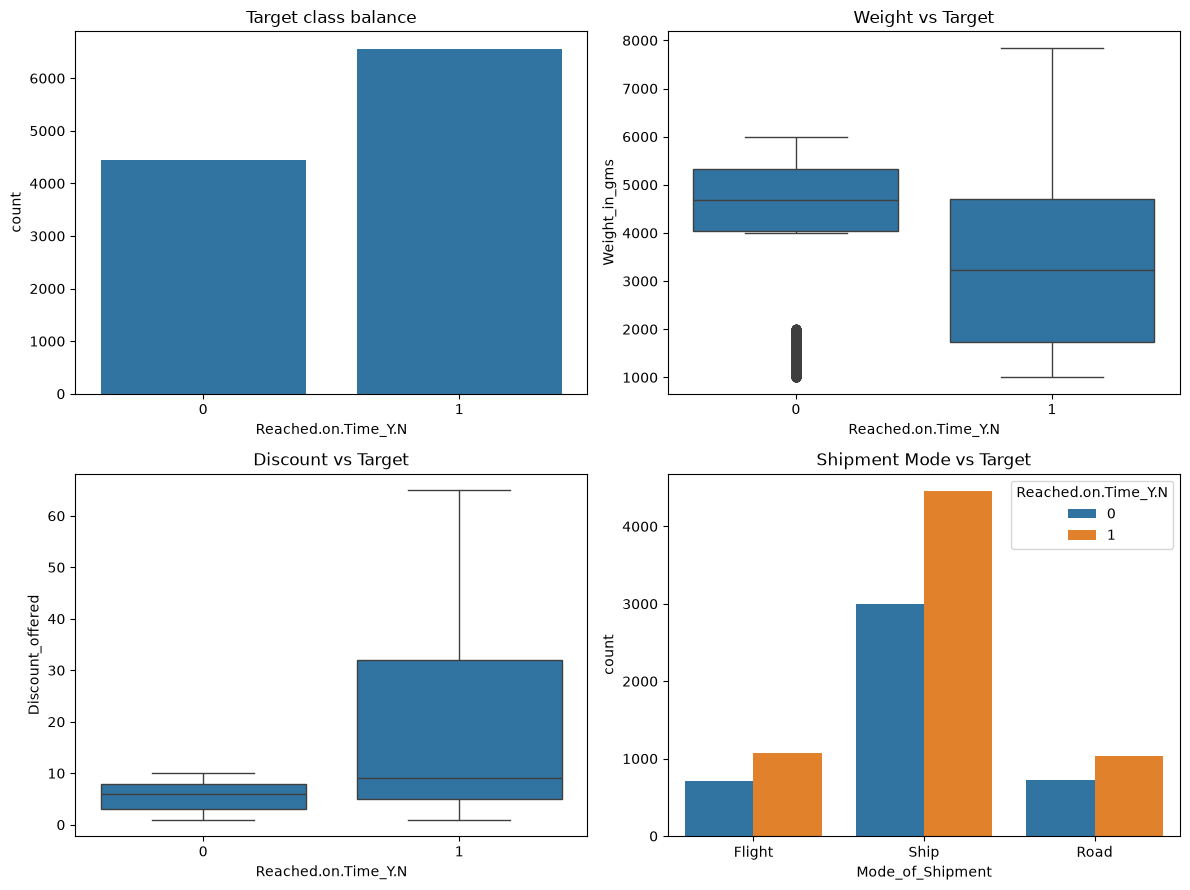

In [191]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.countplot(x=target_col, data=df, ax=axes[0, 0])
axes[0, 0].set_title("Target class balance")

sns.boxplot(x=target_col, y="Weight_in_gms", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Weight vs Target")

sns.boxplot(x=target_col, y="Discount_offered", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Discount vs Target")

sns.countplot(x="Mode_of_Shipment", hue=target_col, data=df, ax=axes[1, 1])
axes[1, 1].set_title("Shipment Mode vs Target")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/eda_overview.png", dpi=120)
plt.show()

Select numerical columns
   num_cols_all = df.select_dtypes(include=np.number).columns
   Selects only the columns containing numerical data.
Create the heatmap
   Calculates the correlation between numerical features and displays it as a heatmap.
annot=True
Displays the correlation values inside the heatmap cells.
cmap=coolwarm
 Uses different colors to represent positive and negative correlations.
fmt=.2f
Displays correlation values rounded to 2 decimal places
Save the figure
   Saves the heatmap in the outputs folder.
Display the plot
Purpose:
The correlation heatmap helps identify the strength and direction of relationships between numerical features and can help detect highly correlated features.


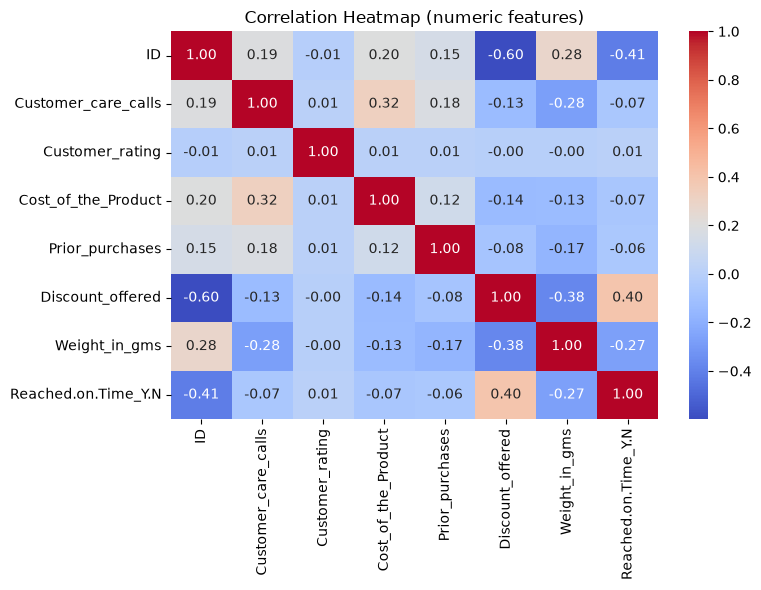

In [192]:
num_cols_all = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols_all].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (numeric features)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/correlation_heatmap.png", dpi=120)
plt.show()

## 3. Feature / Target Split

Separate input features
Removes the target column from the dataset and stores the remaining columns in X.
Select target variable
   Stores the target column Reached.on.Time_Y.N  in y.
Identify categorical columns
   Finds columns containing categorical/text data and stores their names in cat_cols.
Identify numerical columns
   Finds columns containing numerical data and stores their names in num_cols.
This step prepares the data for preprocessing and machine learning model training by separating the target, categorical features, and numerical features.


In [193]:
X = df.drop(columns=[target_col])
y = df[target_col]

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()


C:\Users\pkavy\AppData\Local\Temp\ipykernel_20452\394117800.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns.tolist()


cat_cols → Contains the names of all categorical columns.
num_cols → Contains the names of all numerical columns.
print() → Displays both lists.
This helps verify which columns are categorical and numerical before performing data preprocessing.

In [194]:
print("Categorical columns:", cat_cols)
print("Numeric columns:", num_cols)

Categorical columns: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']
Numeric columns: ['ID', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']


## Feature Engineering

In [195]:
df_fe = df.copy()

In [196]:
df_fe["Discount_per_Cost"] = df_fe["Discount_offered"] / df_fe["Cost_of_the_Product"]

In [197]:
df_fe["Weight_per_PriorPurchase"] = df_fe["Weight_in_gms"] / (df_fe["Prior_purchases"] + 1)

In [198]:
df_fe["CareCalls_per_PriorPurchase"] = df_fe["Customer_care_calls"] / (df_fe["Prior_purchases"] + 1)

In [199]:
df_fe["Weight_Category"] = pd.cut(
    df_fe["Weight_in_gms"],
    bins=[0, 2000, 4000, 6000, np.inf],
    labels=["Light", "Medium", "Heavy", "Very_Heavy"]
).astype(str)

new_feature_cols = ["Discount_per_Cost", "Weight_per_PriorPurchase",
                     "CareCalls_per_PriorPurchase", "Weight_Category"]
print("New engineered features:", new_feature_cols)

New engineered features: ['Discount_per_Cost', 'Weight_per_PriorPurchase', 'CareCalls_per_PriorPurchase', 'Weight_Category']


In [200]:
df_fe[new_feature_cols].describe(include="all")

,Discount_per_Cost,Weight_per_PriorPurchase,CareCalls_per_PriorPurchase,Weight_Category
count,10999.000000,10999.000000,10999.000000,10999
unique,NaN,NaN,NaN,4
top,NaN,NaN,NaN,Heavy
freq,NaN,NaN,NaN,5958
mean,0.070237,891.845171,0.950328,NaN
std,0.092688,500.067763,0.319213,NaN
min,0.003226,100.636364,0.181818,NaN
25%,0.017544,389.696970,0.750000,NaN
50%,0.033333,898.600000,1.000000,NaN
75%,0.062965,1288.750000,1.200000,NaN


## 4. Train / Test Split

train_test_split → Splits the dataset into training and testing sets.
GridSearchCV → Finds the best combination of model hyperparameters using cross-validation.
StratifiedKFold → Performs stratified cross-validation, maintaining a similar proportion of target classes in each fold.
These functions are used to prepare the data and improve the reliability and performance of the machine learning model.

In [201]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold

X → Input features.
y → Target variable.
test_size=0.2 → Uses 20% of the data for testing and 80% for training.
stratify=y → Maintains the same proportion of target classes in both training and testing datasets.
random_state=RANDOM_STATE → Ensures the same split is obtained every time the code is executed.
X_train → Training input features.
X_test → Testing input features.
y_train → Training target values.
y_test → Testing target values.
This step separates the data into training and testing sets so the model can be trained on one portion and evaluated on unseen data.

In [202]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (8799, 11) Test shape: (2200, 11)


## Outlier Detection & Treatment


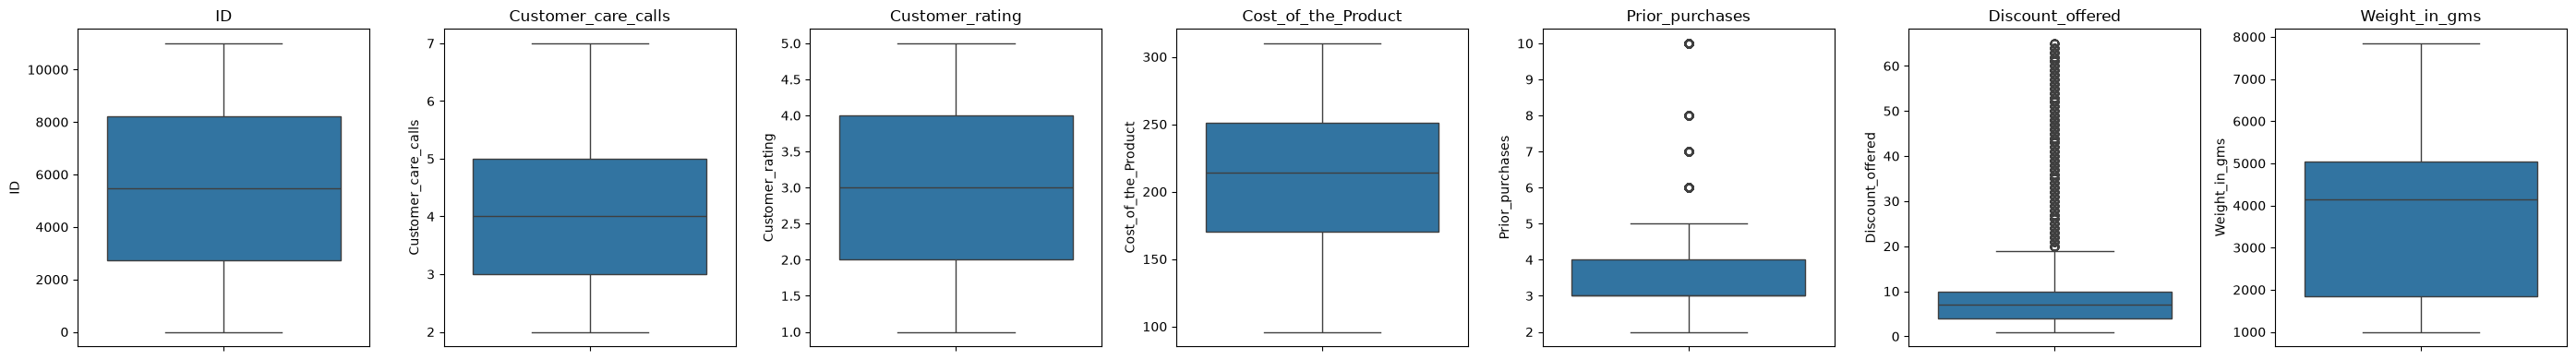

In [203]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/outliers_before.png", dpi=120)
plt.show()

In [204]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


In [205]:
outlier_bounds = {col: iqr_bounds(X_train[col]) for col in num_cols}

In [206]:
outlier_report = []
for col, (low, high) in outlier_bounds.items():
    n_train_out = ((X_train[col] < low) | (X_train[col] > high)).sum()
    outlier_report.append({"feature": col, "lower": round(low, 2),
                            "upper": round(high, 2), "n_outliers_train": n_train_out})

outlier_report_df = pd.DataFrame(outlier_report)
outlier_report_df.to_csv(f"{OUT_DIR}/outlier_report.csv", index=False)
outlier_report_df

,feature,lower,upper,n_outliers_train
0,ID,-5518.5,16433.5,0
1,Customer_care_calls,0.0,8.0,0
2,Customer_rating,-1.0,7.0,0
3,Cost_of_the_Product,48.5,372.5,0
4,Prior_purchases,1.5,5.5,825
5,Discount_offered,-5.0,19.0,1776
6,Weight_in_gms,-2972.5,9855.5,0


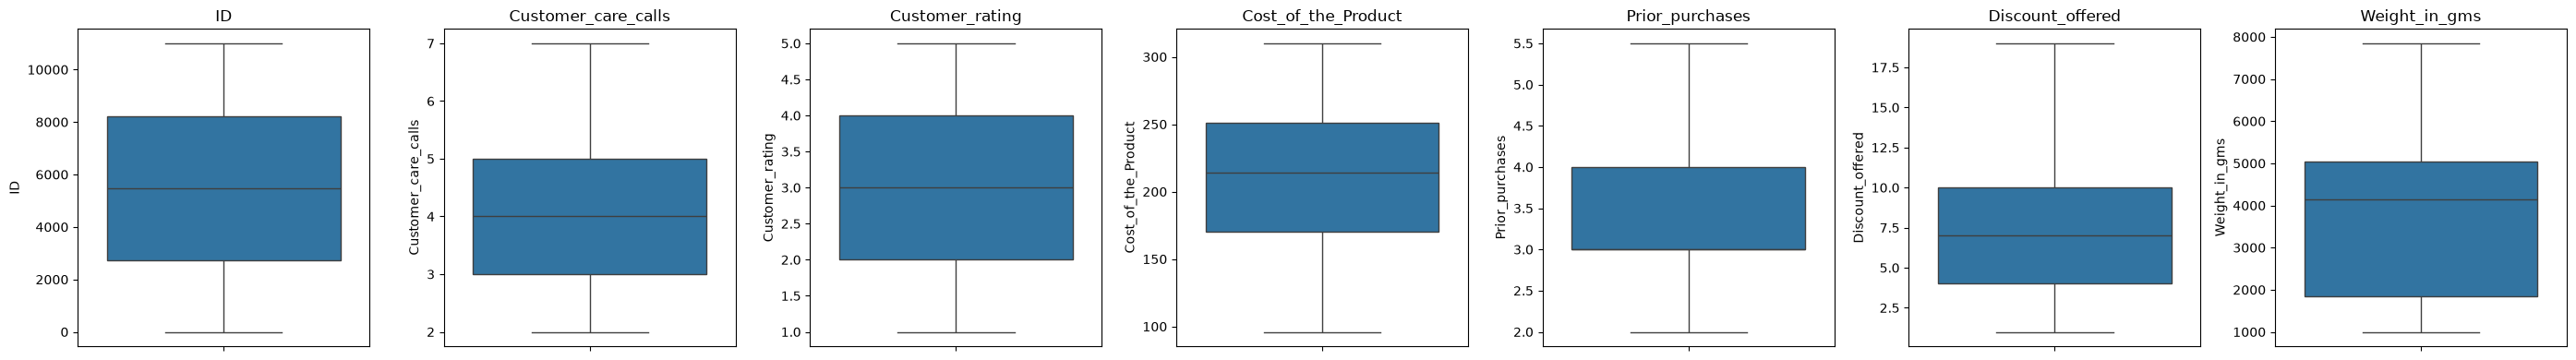

In [207]:
X_train_capped = X_train.copy()
X_test_capped = X_test.copy()

for col, (low, high) in outlier_bounds.items():
    X_train_capped[col] = X_train_capped[col].clip(lower=low, upper=high)
    X_test_capped[col] = X_test_capped[col].clip(lower=low, upper=high)

X_train, X_test = X_train_capped, X_test_capped
del X_train_capped, X_test_capped

fig, axes = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/outliers_after.png", dpi=120)
plt.show()

## 5. Preprocessing 

X_train_num → Contains numerical columns from the training dataset.
X_test_num → Contains numerical columns from the testing dataset.
X_train_cat → Contains categorical columns from the training dataset.
X_test_cat → Contains categorical columns from the testing dataset.
num_cols → List of numerical column names.
cat_cols → List of categorical column names.
This step separates numerical and categorical features so that they can be preprocessed appropriately before training the machine learning model.

In [208]:
X_train_num = X_train[num_cols]
X_test_num = X_test[num_cols]

X_train_cat = X_train[cat_cols]
X_test_cat = X_test[cat_cols]

StandardScaler → Standardizes numerical data by transforming it to have a mean of 0 and a standard deviation of 1.
It is useful when numerical features have different scales.
Standardization helps machine learning algorithms work more effectively when features have different ranges or units.

In [209]:
from sklearn.preprocessing import StandardScaler 

scaler = StandardScaler() → Creates a standardization object.
fit_transform(X_train_num) → Calculates the mean and standard deviation from the training data and then scales the training features.
transform(X_test_num) → Scales the test data using the same values learned from the training data.
X_train_num_scaled → Contains the scaled numerical training features.
X_test_num_scaled → Contains the scaled numerical testing features.
shape → Displays the number of rows and numerical features after scaling.
Standardization puts numerical features on a comparable scale, which can improve the performance of many machine learning algorithms.

In [210]:

scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_num)   
X_test_num_scaled = scaler.transform(X_test_num)         

print("Scaled numeric train shape:", X_train_num_scaled.shape)

Scaled numeric train shape: (8799, 7)


If a column contains:
Mode_of_Shipment = Ship, Flight, Road
One-hot encoding creates separate columns such as:
Ship
Flight
Road
To convert categorical features into a format that can be directly used by machine learning models.

In [211]:
from sklearn.preprocessing import OneHotEncoder

OneHotEncoder(...) → Creates an encoder for categorical variables.
handle_unknown=ignore → Prevents errors if the test data contains a category that was not present in the training data.
drop=first → Removes the first category from each categorical feature to avoid redundant columns.
fit_transform(X_train_cat) → Learns categories from the training data and converts them into numerical values.
transform(X_test_cat) → Converts the test data using the categories learned from the training data.
.toarray() → Converts the encoded sparse matrix into a regular NumPy array.
get_feature_names_out(cat_cols) → Generates the names of the newly created encoded features.
This step converts categorical data into machine-readable numerical features while avoiding unnecessary duplicate information.

In [212]:
encoder = OneHotEncoder(handle_unknown="ignore", drop="first")
X_train_cat_encoded = encoder.fit_transform(X_train_cat).toarray() 
X_test_cat_encoded = encoder.transform(X_test_cat).toarray()         

encoded_feature_names = encoder.get_feature_names_out(cat_cols)

X_train_cat_encoded.shape → Shows the number of rows and encoded categorical features.
encoded_feature_names → Contains the names of the newly created encoded columns.
list(encoded_feature_names) → Converts the feature names into a Python list for easier display.
print() → Displays the results.
This step helps verify that the categorical encoding was performed correctly and shows which new features were created.

In [213]:
print("Encoded categorical train shape:", X_train_cat_encoded.shape)
print("Encoded feature names:", list(encoded_feature_names))

Encoded categorical train shape: (8799, 9)
Encoded feature names: ['Warehouse_block_B', 'Warehouse_block_C', 'Warehouse_block_D', 'Warehouse_block_F', 'Mode_of_Shipment_Road', 'Mode_of_Shipment_Ship', 'Product_importance_low', 'Product_importance_medium', 'Gender_M']


np.hstack()-Horizontally combines arrays column-wise.
X_train_num_scaled-Contains the standardized numerical training features.
X_train_cat_encoded-Contains the one-hot encoded categorical training features.
X_train_processed-Final processed training feature set.
X_test_processed-Final processed testing feature set.
all_feature_names-Combines the original numerical feature names with the newly generated encoded feature names.
This step creates the final input feature matrices that can be given to the machine learning model for training and testing.

In [214]:
X_train_processed = np.hstack([X_train_num_scaled, X_train_cat_encoded])
X_test_processed = np.hstack([X_test_num_scaled, X_test_cat_encoded])

all_feature_names = num_cols + list(encoded_feature_names)

pd.DataFrame()Converts the processed NumPy array into a Pandas DataFrame.
columns=all_feature_names-Assigns the feature names to the columns.
index=X_train.index-Keeps the original training data indexes.
X_train_processed-Final processed training dataset.
X_test_processed-Final processed testing dataset.
X_train_processed.shape-Displays the number of rows and columns in the processed training data.
X_train_processed.head()-Displays the first 5 rows of the processed training data.
This step creates clean and labeled final processed datasets that are ready for machine learning model training.

In [215]:
X_train_processed = pd.DataFrame(X_train_processed, columns=all_feature_names, index=X_train.index)
X_test_processed = pd.DataFrame(X_test_processed, columns=all_feature_names, index=X_test.index)

print("Final processed train shape:", X_train_processed.shape)
X_train_processed.head()

Final processed train shape: (8799, 16)


,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance_low,Product_importance_medium,Gender_M
7920,0.771042,-0.043121,-1.415468,1.056631,-1.258246,0.064139,0.322365,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1529,-1.243047,-0.921405,0.001852,-1.003783,-1.258246,1.703285,-1.206929,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0
10521,1.590734,-0.921405,-0.706808,0.224140,-1.258246,0.064139,0.510849,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0
9558,1.287249,-0.921405,1.419173,-1.107845,0.499592,-1.083264,0.617330,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
968,-1.419843,-1.799688,1.419173,1.285566,-1.258246,1.703285,0.004144,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


## Class Imbalance (Target Imbalance)

--- Class balance in y_train ---
Reached.on.Time_Y.N
1    5250
0    3549
Name: count, dtype: int64
Reached.on.Time_Y.N
1    0.597
0    0.403
Name: proportion, dtype: float64

Minority:Majority ratio = 0.68


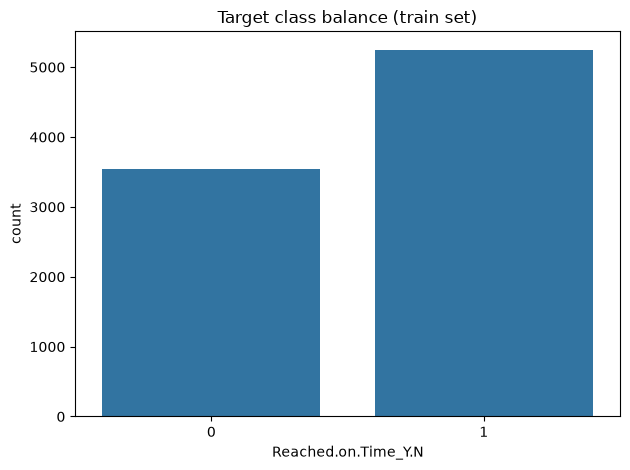

In [216]:
print("--- Class balance in y_train ---")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(3))

imbalance_ratio = y_train.value_counts().min() / y_train.value_counts().max()
print(f"\nMinority:Majority ratio = {imbalance_ratio:.2f}")

sns.countplot(x=y_train)
plt.title("Target class balance (train set)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/class_balance_train.png", dpi=120)
plt.show()

In [217]:
%pip install -U imbalanced-learn    

Note: you may need to restart the kernel to use updated packages.


In [218]:
"import imblearn.over_sampling"

'import imblearn.over_sampling'

In [219]:
try:
    from imblearn.over_sampling import SMOTE
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    print("imbalanced-learn not installed. Install with: pip install imbalanced-learn")

In [220]:
if HAS_IMBLEARN:
    smote = SMOTE(random_state=RANDOM_STATE)
    X_train_res, y_train_res = smote.fit_resample(X_train_processed, y_train)
    print("Before SMOTE:", y_train.value_counts().to_dict())
    print("After SMOTE: ", y_train_res.value_counts().to_dict())
else:
    X_train_res, y_train_res = X_train_processed, y_train
    print("SMOTE unavailable — relying on class_weight='balanced' during training/tuning.") 

Before SMOTE: {1: 5250, 0: 3549}
After SMOTE:  {0: 5250, 1: 5250}


## 6. Train Multiple Models

sklearn.linear_model-Module containing linear-based machine learning algorithms.
LogisticRegression-Classification algorithm used to predict categorical target classes.
In this project, it can be used to predict whether the shipment reached on time or not.
This step makes the LogisticRegression model available for training and classification.

In [221]:
from sklearn.linear_model import LogisticRegression


sklearn.tree-Module containing tree-based machine learning algorithms.
DecisionTreeClassifier-A supervised machine learning algorithm used for classification.
It makes predictions by creating a series of decision rules based on the input features.
This step makes the DecisionTreeClassifier available for training and predicting the target class.


In [222]:
from sklearn.tree import DecisionTreeClassifier

RandomForestClassifier-Builds multiple decision trees and combines their predictions to perform classification.
GradientBoostingClassifier-Builds decision trees sequentially, where each new tree tries to correct errors made by the previous trees.
sklearn.ensemble-Module that contains ensemble learning algorithms.
These algorithms can be trained and compared to determine which model performs best for predicting whether the shipment reached on time or not.

In [223]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

LogisticRegression-A classification algorithm that predicts the probability of a class.
max_iter=1000-Allows up to 1000 iterations for model convergence.
DecisionTree-Makes predictions using a tree-like structure of decision rules.
RandomForest-Combines multiple decision trees to improve prediction performance.
n_estimators=300-Creates 300 decision trees.
GradientBoosting-Builds multiple trees sequentially, with each tree trying to improve the errors of previous trees.
random_state=RANDOM_STATE-Keeps the results reproducible.
This step prepares multiple classification models so they can be trained and compared to find the best model for predicting Reached.on.Time_Y.N.

In [224]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=300),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

results =Creates an empty dictionary to store the performance results of each machine learning model, such as accuracy, precision, recall, or F1-score.
fitted_models =Creates an empty dictionary to store the trained (fitted) models.
These dictionaries allow us to keep the evaluation results and trained models organized for later comparison and prediction.

In [225]:
results = {}
fitted_models = {}

models.items()Retrieves each model's name and model object from the models dictionary.
name-Stores the name of the current model.
model-Stores the current machine learning model.
model.fit(X_train_processed, y_train)-Trains the model using the processed training features and target values.
model.predict(X_test_processed)-Uses the trained model to predict the target values for the test dataset.
preds-Stores the predicted target values.
This step trains all the selected models and generates predictions on unseen test data so their performance can be evaluated.

In [226]:
for name, model in models.items():
    model.fit(X_train_processed, y_train)
    preds = model.predict(X_test_processed)

accuracy_score-Measures the percentage of correctly predicted samples.
precision_score-Measures how many of the predicted positive cases are actually positive.
recall_score-Measures how many of the actual positive cases are correctly identified.
f1_score-Combines precision and recall into a single score.
roc_auc_score-Measures how well the model distinguishes between the two classes.
confusion_matrix-Shows the number of correct and incorrect predictions for each class.
These metrics are used to evaluate and compare the performance of the classification models.

In [227]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,)

for name, model in models.items()-Loops through all the models stored in the models dictionary.
model.fit(X_train_processed, y_train)-Trains the current model using the processed training data.
model.predict(X_test_processed)-Predicts the target class for the test data.
preds-Stores the predicted class labels.
model.predict_proba(X_test_processed)-Calculates the probability of each class.
Selects the probability of class 1, which represents the positive class.
proba-Stores the predicted probabilities for class 1.
This step prepares both class predictions and prediction probabilities, which are needed to calculate evaluation metrics such as accuracy, precision, recall, F1-score, and ROC-AUC.

In [228]:
for name, model in models.items():
    model.fit(X_train_processed, y_train)
    preds = model.predict(X_test_processed)
    proba = model.predict_proba(X_test_processed)[:, 1]

classification_report-Provides a summary of the model's classification performance.
It displays:
Precision
Recall
F1-score
Support(number of actual samples in each class)
It helps evaluate how well the model performs for each target class.


In [229]:
from sklearn.metrics import classification_report

In [230]:
results[name] = {
        "accuracy": accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds),
        "recall": recall_score(y_test, preds),
        "f1": f1_score(y_test, preds),
        "roc_auc": roc_auc_score(y_test, proba),
    }
fitted_models[name] = model
print(f"=== {name} ===")
print(classification_report(y_test, preds))

=== GradientBoosting ===
              precision    recall  f1-score   support

           0       0.56      0.94      0.71       887
           1       0.93      0.51      0.66      1313

    accuracy                           0.68      2200
   macro avg       0.75      0.73      0.68      2200
weighted avg       0.78      0.68      0.68      2200



## 7. Compare Models

In [231]:
results_df = pd.DataFrame(results).T.sort_values("roc_auc", ascending=False)
results_df.to_csv(f"{OUT_DIR}/model_comparison.csv")
results_df

,accuracy,precision,recall,f1,roc_auc
GradientBoosting,0.682727,0.931276,0.505712,0.655479,0.748848


## 8. Hyperparameter Tuning (on the best baseline model)

In [238]:
best_model_name = results_df.index[0]
print("Best baseline model:", best_model_name)

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [8, 12, None],
    "min_samples_split": [2, 5],
}

if best_model_name == "RandomForest":
    grid = GridSearchCV(
        RandomForestClassifier(random_state=RANDOM_STATE),
        param_grid,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        scoring="roc_auc", n_jobs=-1
    )
    grid.fit(X_train_processed, y_train)
    print("Best params:", grid.best_params_)
    best_model = grid.best_estimator_
else:
    best_model = fitted_models[best_model_name]

Best baseline model: GradientBoosting


## 9. Final Evaluation on Test Set

In [239]:
final_preds = best_model.predict(X_test_processed)
final_proba = best_model.predict_proba(X_test_processed)[:, 1]

In [240]:
final_metrics = {
    "accuracy": accuracy_score(y_test, final_preds),
    "precision": precision_score(y_test, final_preds),
    "recall": recall_score(y_test, final_preds),
    "f1": f1_score(y_test, final_preds),
    "roc_auc": roc_auc_score(y_test, final_proba),
}

In [241]:
import json

In [242]:
print(json.dumps(final_metrics, indent=2))

with open(f"{OUT_DIR}/final_metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=2)

{
  "accuracy": 0.6827272727272727,
  "precision": 0.9312762973352033,
  "recall": 0.5057121096725057,
  "f1": 0.6554787759131293,
  "roc_auc": 0.7488483476740702
}


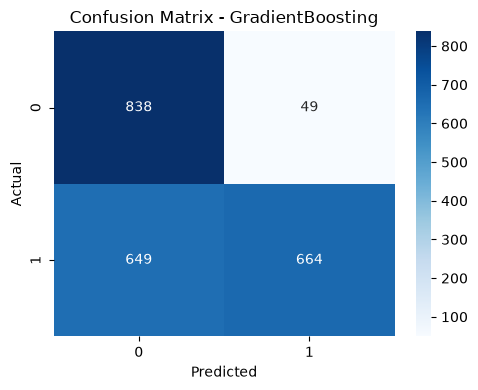

In [243]:
cm = confusion_matrix(y_test, final_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=120)
plt.show()

In [244]:
from sklearn.metrics import RocCurveDisplay

<Figure size 500x400 with 0 Axes>

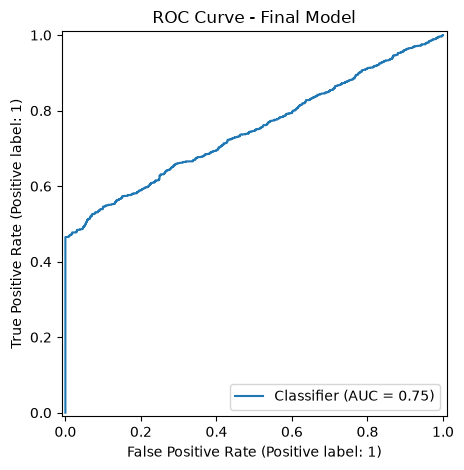

In [245]:
plt.figure(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_test, final_proba)
plt.title("ROC Curve - Final Model")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/roc_curve.png", dpi=120)
plt.show()

### Feature Importance (tree-based models)

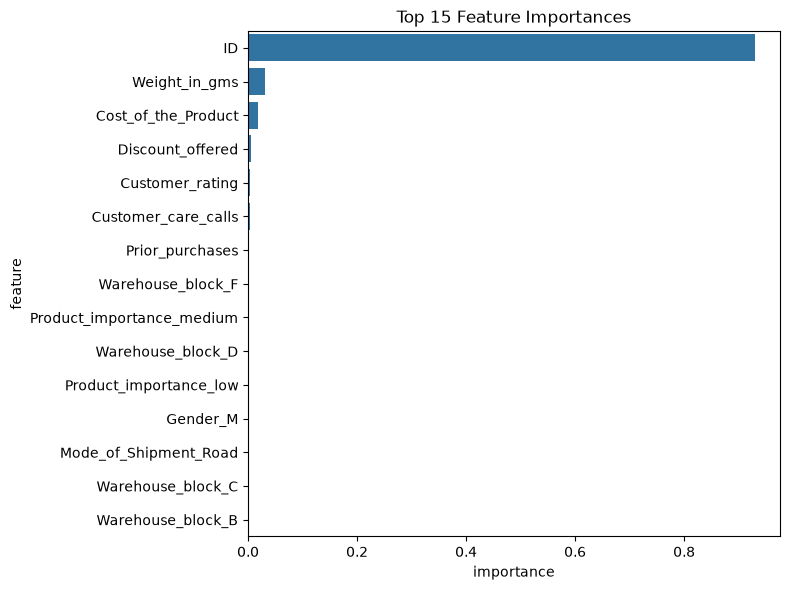

In [246]:
try:
    importances = best_model.feature_importances_
    fi_df = pd.DataFrame({"feature": all_feature_names, "importance": importances}).sort_values("importance", ascending=False)
    fi_df.to_csv(f"{OUT_DIR}/feature_importance.csv", index=False)

    plt.figure(figsize=(8, 6))
    sns.barplot(x="importance", y="feature", data=fi_df.head(15))
    plt.title("Top 15 Feature Importances")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/feature_importance.png", dpi=120)
    plt.show()
except Exception as e:
    print("Feature importance not available for this model type:", e)


## 10. Save the Final Model + Preprocessing Objects

In [247]:
joblib.dump(best_model, f"{OUT_DIR}/final_model.pkl")
joblib.dump(scaler, f"{OUT_DIR}/scaler.pkl")
joblib.dump(encoder, f"{OUT_DIR}/encoder.pkl")

with open(f"{OUT_DIR}/feature_columns.json", "w") as f:
    json.dump({"num_cols": num_cols, "cat_cols": cat_cols}, f, indent=2)

print(f"Saved model ({best_model_name}), scaler, and encoder to '{OUT_DIR}/'")

Saved model (GradientBoosting), scaler, and encoder to 'outputs/'


## 11. Load Model + Preprocessors & Predict on New Data

In [248]:
loaded_model = joblib.load(f"{OUT_DIR}/final_model.pkl")
loaded_scaler = joblib.load(f"{OUT_DIR}/scaler.pkl")
loaded_encoder = joblib.load(f"{OUT_DIR}/encoder.pkl")

In [249]:
with open(f"{OUT_DIR}/feature_columns.json") as f:
    cols = json.load(f)
loaded_num_cols, loaded_cat_cols = cols["num_cols"], cols["cat_cols"]

In [250]:
sample_raw = X_test.iloc[:5]

In [251]:
sample_num_scaled = loaded_scaler.transform(sample_raw[loaded_num_cols])
sample_cat_encoded = loaded_encoder.transform(sample_raw[loaded_cat_cols]).toarray()
sample_processed = np.hstack([sample_num_scaled, sample_cat_encoded])

In [252]:
print("Predictions:", loaded_model.predict(sample_processed))
print("Probabilities:", loaded_model.predict_proba(sample_processed)[:, 1])

Predictions: [1 1 0 0 0]
Probabilities: [0.99448176 0.50150255 0.44893628 0.43179369 0.41851531]


c:\Users\pkavy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
c:\Users\pkavy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
